# 04 - Parte 2: modelos M2, M3 e M4, experimentos E1 a E4

**Projeto:** classificar 20 espécies de aves pelo canto (BirdCLEF 2025), comparando redes treinadas do zero com redes pré-treinadas em áudio. Disciplina CIN0040 (UFPE). A Parte 1 (notebooks 01 a 03) montou os dados, o pipeline e o primeiro modelo (M1); este notebook faz a comparação entre arquiteturas, que é o centro do trabalho.

**Hipóteses que este notebook testa**

| | Hipótese | Onde é testada |
|---|---|---|
| **H1** | Os modelos pré-treinados no AudioSet (M3, M4) superam os treinados do zero (M1, M2) em F1-macro, sobretudo com poucos dados | E1 (seções 4 e 5) e E4 (seção 7) |
| **H2** | A CRNN (M2) supera a CNN (M1) de mesmo porte | E1 (seções 4 e 5) |
| **H3** | O aumento de dados reduz a queda de desempenho sob ruído (SNR ≤ 10 dB) | E2b + E3b (seção 6) |

**Os quatro modelos**

| ID | O que é | Inicialização | Entrada |
|---|---|---|---|
| M1 | CNN de 4 blocos (Parte 1) | aleatória | log-Mel 128 × 313 |
| M2 | CRNN: 4 blocos convolucionais + GRU bidirecional no tempo | aleatória | log-Mel 128 × 313 |
| M3 | PANNs CNN14, ajuste fino completo | AudioSet | log-Mel 64 × 501 |
| M4 | AST (*Audio Spectrogram Transformer*) congelado + cabeça linear | AudioSet | embedding de 768 dimensões |

**Protocolo (o mesmo da Parte 1):** cada gravação vira até 12 janelas de 5 s; a divisão é **por gravação** (janelas de uma gravação nunca ficam em partições diferentes); o **teste fixo tem 600 gravações** e só é usado na avaliação final; nas outras 2400 há validação cruzada de 5 folds. A predição de uma gravação é a média das probabilidades das suas janelas. A métrica principal é o **F1-macro** (média do F1 das 20 espécies, que pesa todas igualmente).

**Como ler este notebook:** cada etapa começa com uma célula que explica *o que* é feito, *por que* (qual hipótese ou risco ela trata) e *como interpretar* a saída; depois de cada resultado importante há uma leitura dos números. Todo o código fica em `src/birdclef/`; aqui ele só é chamado.

**Retomada:** cada treino vira um checkpoint em `checkpoints/<modelo>_<aumento>_s<semente>_f<fold>.pt` e é pulado se já existir. Com os checkpoints presentes, o notebook roda do início ao fim em poucos minutos ("Restart & Run All"), só reavaliando.

## 0. Ambiente e dados

**O que:** confere a GPU, as versões e se os arquivos gerados pelos notebooks 01 e 02 existem.
**Por que:** os modelos foram treinados numa GPU de notebook com 4 GB de VRAM, o que restringe lotes e escolhas (por exemplo, o AST congelado no M4). Registrar o hardware deixa os tempos de treino interpretáveis.

In [1]:
import os, sys, json, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from birdclef import dados, preproc, aumento, modelos, treino, analise, graficos
from birdclef import experimentos_p2 as e
from birdclef.experimentos import carregar_checkpoint, dados_teste, PASTA_CHECKPOINTS
import transformers; transformers.logging.set_verbosity_error(); transformers.logging.disable_progress_bar()
%matplotlib inline
pd.set_option("display.precision", 3)

def ms(s):  # "média ± desvio" com 3 casas
    return f"{s.mean():.3f} ± {s.std():.3f}"

prop = torch.cuda.get_device_properties(0) if torch.cuda.is_available() else None
print(f"torch {torch.__version__} | CUDA {torch.version.cuda} | GPU: {prop.name if prop else 'nenhuma'}"
      + (f" ({prop.total_memory / 2**30:.1f} GiB de VRAM)" if prop else ""))
arquivos = ["dados/subconjunto/divisoes.csv", "dados/espectrogramas/mel128_32k/X.npy", "dados/ruido/ruido.csv",
            "dados/bruto/train_audio", "checkpoints/pretreinados/Cnn14_mAP=0.431.pth"]
display(pd.DataFrame({"arquivo": arquivos, "existe": [Path(p).exists() for p in arquivos]}))

torch 2.11.0+cu128 | CUDA 12.8 | GPU: NVIDIA GeForce RTX 3050 Laptop GPU (4.0 GiB de VRAM)


,arquivo,existe
0,dados/subconjunto/divisoes.csv,True
1,dados/espectrogramas/mel128_32k/X.npy,True
2,dados/ruido/ruido.csv,True
3,dados/bruto/train_audio,True
4,checkpoints/pretreinados/Cnn14_mAP=0.431.pth,True


### 0.1 Reprodutibilidade da Parte 1

**O que:** recarrega o checkpoint `M1_todas_s42_f0.pt` (treinado na Parte 1) e o avalia no teste limpo, com os espectrogramas regenerados nesta máquina a partir dos áudios.
**Por que:** antes de comparar modelos novos com o M1, é preciso garantir que dados, divisões e pré-processamento são *exatamente* os da Parte 1. Se o F1 não bater com o registrado em `resultados/e2/e2_execucoes.csv` (tolerância 0,005), qualquer comparação seria entre pipelines diferentes.
**Como ler:** a coluna `diferença` deve ser ≈ 0.

In [2]:
X128, jan = preproc.carregar(preproc.MEL128_32K)
r = carregar_checkpoint(PASTA_CHECKPOINTS / "M1_todas_s42_f0.pt", "M1")
m_rep, _, _ = treino.avaliar_teste(r, *dados_teste(X128, jan))
ref = pd.read_csv("resultados/e2/e2_execucoes.csv").query("aumento == 'todas' and semente == 42").iloc[0]
rep = pd.DataFrame({"métrica": ["F1-macro", "top-1", "top-3", "mAP"],
                    "Parte 1 (registrado)": [ref.teste_f1_macro, ref.teste_acc_top1, ref.teste_acc_top3, ref.teste_map],
                    "agora": [m_rep["f1_macro"], m_rep["acc_top1"], m_rep["acc_top3"], m_rep["map"]]})
rep["diferença"] = rep["agora"] - rep["Parte 1 (registrado)"]
display(rep.round(4))
assert abs(rep.loc[0, "diferença"]) < 0.005, "o pipeline não reproduz a Parte 1"

,métrica,Parte 1 (registrado),agora,diferença
0,F1-macro,0.879,0.879,0.0
1,top-1,0.877,0.877,0.0
2,top-3,0.962,0.962,0.0
3,mAP,0.926,0.926,0.0


> **Leitura.** O checkpoint da Parte 1, avaliado nos espectrogramas regenerados nesta máquina, dá **exatamente** o F1 registrado (diferença 0,0000, também em top-1, top-3 e mAP). Dados, divisões, janelas e pré-processamento são os mesmos da Parte 1, então tudo o que vem a seguir é comparável com ela.

## 1. Entradas do M3 e do M4

**O que:** gera, a partir dos mesmos áudios e das mesmas janelas, as entradas dos modelos pré-treinados:

- **M3 (PANNs CNN14):** log-Mel na configuração original do PANNs (32 kHz, `n_fft` 1024, *hop* 320 = 10 ms, 64 bandas, 50 a 14 000 Hz → 64 × 501). Também gera os ruídos de treino e o teste ruidoso do E3 nessa configuração.
- **M4 (AST):** cada janela passa uma vez pelo AST pré-treinado (a 16 kHz, como no treino original dele) e guardamos o embedding de 768 dimensões.

**Por que assim:** um modelo pré-treinado só aproveita o que aprendeu se receber a entrada no formato em que foi treinado; por isso cada um tem o seu log-Mel. O AST tem 87 milhões de parâmetros e processa 1214 *tokens* por janela: o ajuste fino completo não cabe em 4 GB de VRAM, mas a passagem direta sem gradiente cabe. Então o M4 é um *linear probe*: o AST fica congelado e só uma camada linear é treinada. É a forma padrão de medir a qualidade de uma representação pré-treinada, mas tem uma consequência: **o M4 não usa aumento de dados** (o embedding é fixo).

**Como ler:** a célula pula o que já existe. A figura mostra a mesma janela nas três representações.

W1122 08:51:24.337000 26432 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


,entrada,modelos,forma de X,tamanho (GB)
0,mel128_32k,"M1, M2","(23635, 128, 313)",1.76
1,mel64_32k,M3,"(23635, 64, 501)",1.41
2,ast_emb,M4,"(23635, 768)",0.03


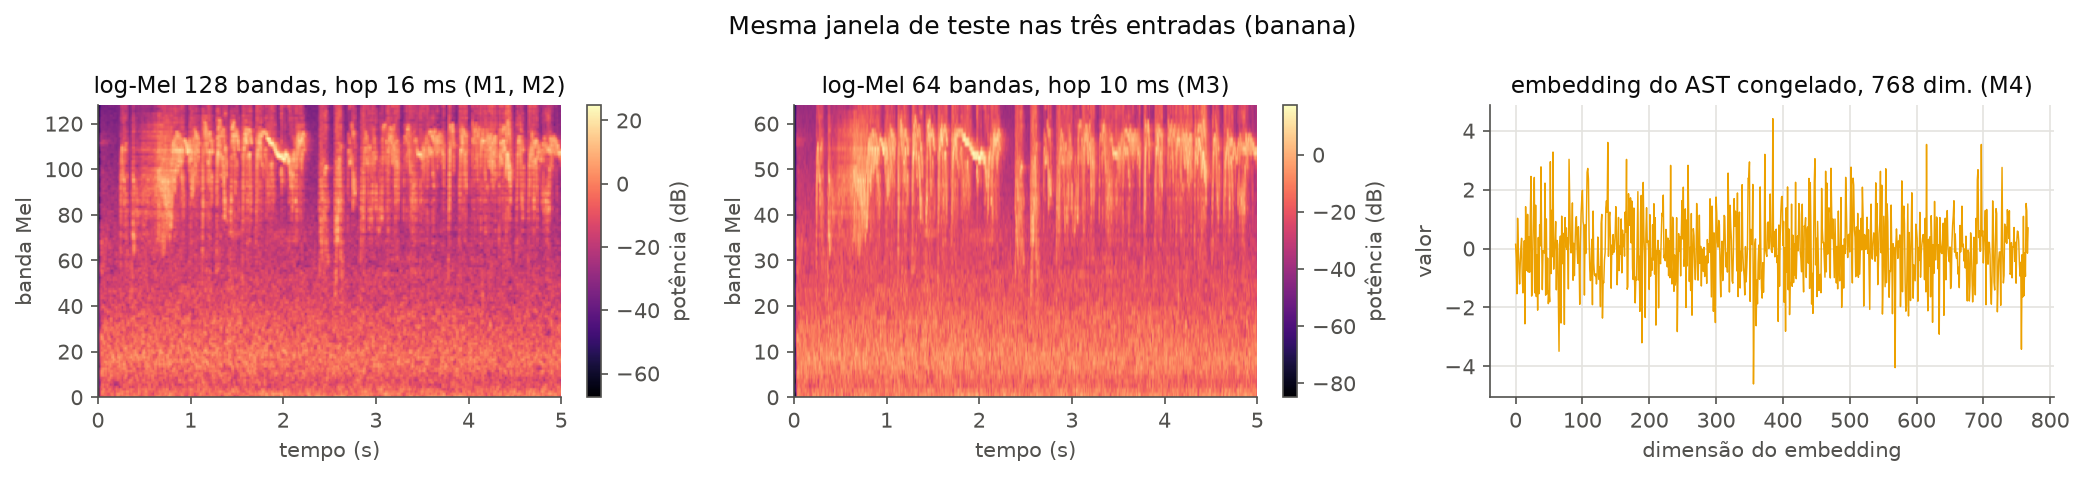

In [3]:
from birdclef import ast_emb
div = pd.read_csv(dados.pasta_dados() / "subconjunto" / "divisoes.csv")
cfg64 = preproc.MEL64_32K
p64 = preproc.pasta_config(cfg64)
if not (p64 / "X.npy").exists():
    preproc.preprocessar(div, cfg64)
if not (p64 / "R.npy").exists():
    aumento.preparar_ruido_treino(cfg64)
if not (p64 / "janelas_teste.csv").exists():
    aumento.preparar_teste_ruidoso(cfg64)
ast_emb.gerar()  # pula o que já existe

X64, _ = preproc.carregar(cfg64)
Xast, _ = preproc.carregar(preproc.AST_EMB)
display(pd.DataFrame([{"entrada": n, "modelos": mods, "forma de X": str(x.shape), "tamanho (GB)": x.nbytes / 2**30}
                      for n, mods, x in [("mel128_32k", "M1, M2", X128), ("mel64_32k", "M3", X64), ("ast_emb", "M4", Xast)]]).round(2))
i0 = int(np.flatnonzero((jan.particao == "teste").to_numpy())[0])
graficos.entradas(X128[i0], X64[i0], Xast[i0], f"Mesma janela de teste nas três entradas ({jan.primary_label.iloc[i0]})",
                  Path("resultados/e1/entradas.png"))
display(Image("resultados/e1/entradas.png"))

## 2. As três entradas têm as mesmas janelas?

**O que:** compara arquivo, início, partição e fold de cada janela das três entradas.
**Por que:** é o risco mais traiçoeiro de uma comparação entre modelos com pré-processamentos diferentes: se uma entrada descartasse ou deslocasse janelas, os modelos seriam avaliados em amostras diferentes e as diferenças de F1 não seriam atribuíveis à arquitetura. O recorte depende só da forma de onda a 32 kHz, então deve sair idêntico.
**Como ler:** todas as linhas devem vir `True`; se não, a célula para.

In [4]:
chk = e.checar_mesmas_janelas()
display(chk)
assert chk["iguais_ao_mel128_32k"].all()

,entrada,janelas,iguais_ao_mel128_32k
0,mel128_32k,23635,True
1,mel64_32k,23635,True
2,ast_emb,23635,True
3,ast_fbank,23635,True


## 3. Os modelos e seus hiperparâmetros

**O que:** instancia os quatro modelos e mostra o tamanho e a configuração de treino de cada um.

**Decisões de projeto (e por quê):**

- **M2 do mesmo porte que o M1** (~375 mil contra ~393 mil parâmetros): H2 pergunta se *modelar o tempo* (a GRU) ajuda; se o M2 fosse maior, uma vitória dele poderia ser só capacidade.
- **M1 e M2 com os hiperparâmetros da Parte 1** (AdamW, lr 1e-3, cosseno, até 30 épocas, paciência 6, lote 64): nada foi reajustado para o M2, para não favorecê-lo.
- **M3 com lote 16 e taxas discriminativas:** o CNN14 tem 80 milhões de parâmetros. Com lote 16 e precisão mista o pico de memória é ~1,7 GiB, o que cabe com folga em 4 GB, então não foi preciso reduzir o lote para 8 nem acumular gradiente. O corpo pré-treinado usa lr 1e-4 e a camada nova 1e-3, para não apagar o que veio do AudioSet. Converge em poucas épocas: até 15, paciência 4.
- **SpecAugment reescalado no M3:** as máscaras são definidas em bandas e quadros; com 64 bandas e quadros de 10 ms elas passam a 8 bandas e 64 quadros, cobrindo a mesma fração do espectro e o mesmo tempo (~0,64 s) que no M1.
- **M4:** só uma camada linear (~15 mil parâmetros): treino barato, então mais épocas (60) e paciência (10).

**Como ler:** `parametros` são os treináveis.

In [5]:
linhas = []
for m in e.MODELOS:
    c = e.CFG_TREINO[m]
    linhas.append({"modelo": m, "entrada": modelos.ENTRADA[m],
                   "parâmetros": f"{modelos.n_parametros(modelos.criar(m, 20, pretreinado=False)):,}".replace(",", "."),
                   "épocas (máx.)": c.epocas, "paciência": c.paciencia, "lote": c.lote, "lr": c.lr,
                   "lr do corpo": c.lr_backbone or "-", "aumento no E1": e.aumento_de(m, e.nome_aumento_e1(m)).nome})
display(pd.DataFrame(linhas).set_index("modelo"))

,entrada,parâmetros,épocas (máx.),paciência,lote,lr,lr do corpo,aumento no E1
modelo,,,,,,,,
M1,mel128_32k,393.460,30,6,64,0.001,-,specaug+mixup+ruido
M2,mel128_32k,374.644,30,6,64,0.001,-,specaug+mixup+ruido
M3,mel64_32k,79.714.772,15,4,16,0.001,0.0,specaug+mixup+ruido
M4,ast_emb,15.380,60,10,128,0.001,-,sem


## 4. E1: comparação das arquiteturas (H1, H2)

**O que:** cada modelo é treinado 5 vezes, uma por fold (o fold *k* é a validação e os outros 4 são treino), com a mesma configuração de aumento (SpecAugment + mixup + ruído; o M4 não tem aumento). Cada um dos 5 modelos é avaliado no **mesmo teste de 600 gravações**. Reportamos a média ± desvio dos 5 e o *ensemble* dos 5 (média das probabilidades). O fold 0 do M1 é o próprio `M1_todas_s42_f0` da Parte 1.

**Por que 5 folds:** com 600 gravações de teste, um único treino tem variação de ~1 ponto de F1 só por causa da semente e dos dados de treino. Cinco treinos dão uma ideia dessa variação e permitem comparações pareadas (mesmo fold).

**Como ler:** a tabela mostra validação e teste. A validação serve para parar o treino; o número que importa para as hipóteses é o de teste. A figura mostra os 5 folds (pontos), a média (barra) e o ensemble (losango).

Com os checkpoints presentes, esta célula só reavalia o teste (alguns minutos, o M3 é o mais lento).

M1_todas_s42_f0: F1 val 0.858  F1 teste 0.879  (0.1 min)


M1_todas_s42_f1: F1 val 0.860  F1 teste 0.874  (0.0 min)


M1_todas_s42_f2: F1 val 0.856  F1 teste 0.873  (0.0 min)


M1_todas_s42_f3: F1 val 0.889  F1 teste 0.882  (0.0 min)


M1_todas_s42_f4: F1 val 0.876  F1 teste 0.892  (0.0 min)


M2_todas_s42_f0: F1 val 0.848  F1 teste 0.869  (0.0 min)


... (11 outputs left out)

M3_todas_s42_f2: F1 val 0.944  F1 teste 0.944  (0.3 min)


M3_todas_s42_f3: F1 val 0.934  F1 teste 0.924  (0.3 min)


M3_todas_s42_f4: F1 val 0.917  F1 teste 0.943  (0.3 min)


,F1 val.,F1 teste,top-1 teste,top-3 teste,mAP teste,épocas,min/treino,"F1 teste, ensemble dos 5"
modelo,,,,,,,,
M1,0.868 ± 0.015,0.880 ± 0.008,0.879 ± 0.008,0.962 ± 0.004,0.933 ± 0.007,27.6,11.4,0.9
M2,0.865 ± 0.028,0.867 ± 0.045,0.866 ± 0.046,0.956 ± 0.019,0.929 ± 0.028,21.6,8.9,0.9
M3,0.929 ± 0.010,0.938 ± 0.008,0.938 ± 0.008,0.982 ± 0.006,0.969 ± 0.007,14.6,48.5,0.9
M4,0.828 ± 0.009,0.824 ± 0.008,0.826 ± 0.008,0.947 ± 0.005,0.888 ± 0.003,30.0,0.1,0.8


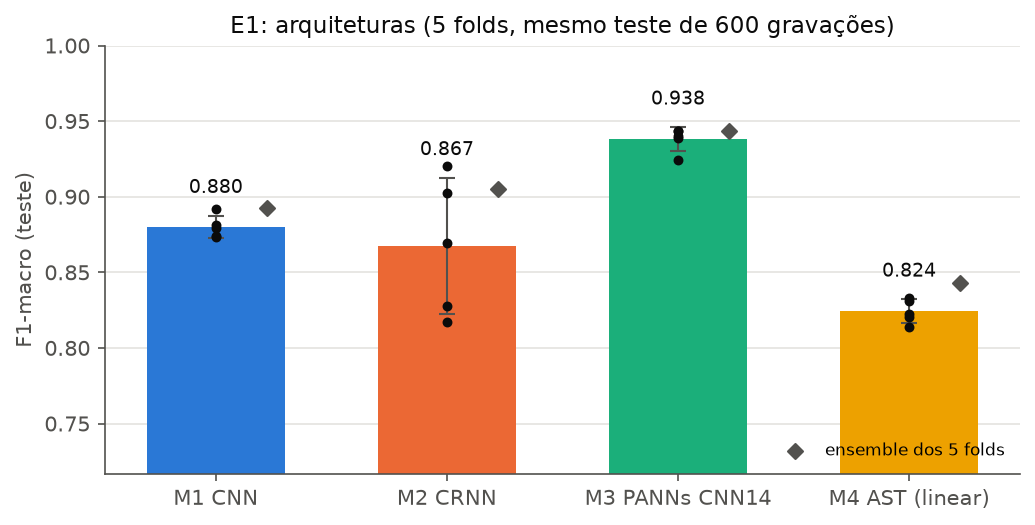

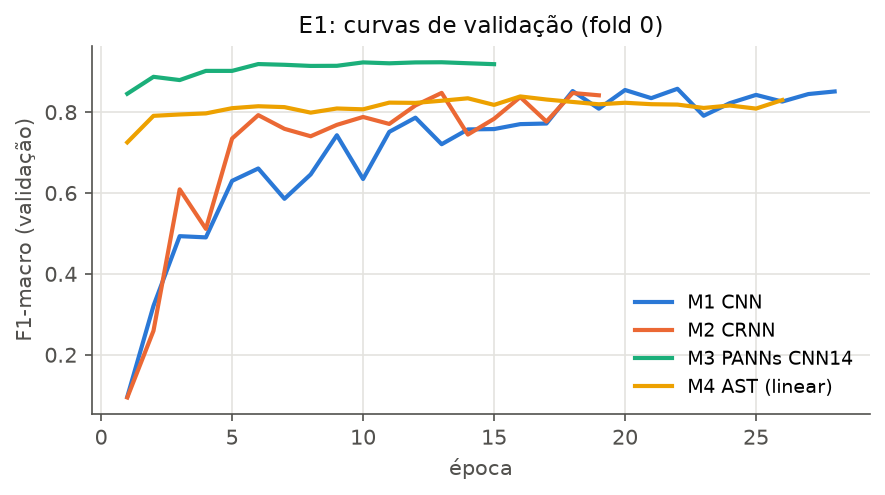

In [6]:
_ = e.e1(("M1", "M2", "M4"))
_ = e.e1(("M3",))
df1 = pd.read_csv("resultados/e1/e1_execucoes.csv")
ens1 = pd.read_csv("resultados/e1/e1_ensemble.csv").set_index("modelo")
tab1 = df1.groupby("modelo").agg(**{
    "F1 val.": ("val_f1_macro", ms), "F1 teste": ("teste_f1_macro", ms), "top-1 teste": ("teste_acc_top1", ms),
    "top-3 teste": ("teste_acc_top3", ms), "mAP teste": ("teste_map", ms),
    "épocas": ("epocas", "mean"), "min/treino": ("minutos", "mean")}).reindex(e.MODELOS)
tab1["F1 teste, ensemble dos 5"] = ens1["f1_macro"].reindex(e.MODELOS).round(3)
display(tab1.round(1))
graficos.e1_barras(df1, ens1.reset_index()); graficos.e1_curvas()
display(Image("resultados/e1/e1_f1_teste.png")); display(Image("resultados/e1/e1_curvas.png"))

> **Leitura.**
>
> - **M3 (PANNs) é o melhor com folga:** F1 de teste 0,938 ± 0,008 nos 5 folds e 0,944 no ensemble, com top-3 de 0,992 (em 99% das gravações a espécie certa está entre as 3 primeiras). Ganha do M1 em ~6 pontos e com desvio igual ao do M1: o ganho não é sorte de um fold.
> - **M1 (CNN do zero)** fica em 0,880 ± 0,008: estável e bem acima da linha de base clássica do notebook 05 (0,55).
> - **M2 (CRNN)** tem média um pouco abaixo do M1 (0,867), mas um desvio **5 vezes maior** (± 0,045): nos folds 0, 2 e 4 vai de 0,869 a 0,920, enquanto nos folds 1 e 3 a parada antecipada o interrompeu cedo (melhor época 7 e 10, contra 13 a 29 nos outros) e ele fica em 0,817 e 0,828. A GRU torna o treino mais instável com os hiperparâmetros do M1, que foram mantidos de propósito para não favorecê-lo. Curiosamente, o **ensemble** do M2 (0,905) supera o do M1 (0,893): os 5 M2 erram em lugares diferentes e a média compensa.
> - **M4 (AST congelado)** é o pior (0,824 ± 0,008), apesar de pré-treinado. Usa só uma camada linear sobre um embedding fixo, sem ajuste fino e sem aumento de dados. Em compensação, treina em **8 segundos**, contra ~11 min do M1 e ~49 min do M3.
> - **Custo:** o M3 tem 80 milhões de parâmetros e leva ~4 vezes mais tempo por treino que o M1, que tem ~0,4 milhão.
>
> As curvas mostram o M3 convergindo em ~13 épocas (o pré-treino já traz bons filtros), enquanto M1 e M2 precisam de 20 a 30.

## 5. As diferenças são consistentes? (H1, H2)

**O que:** duas formas de comparar cada par de modelos A − B no teste:

- **por fold (pareado):** a diferença de F1 entre A e B treinados no mesmo fold; `folds_A_melhor` conta em quantos dos 5 o A ganhou;
- ***bootstrap* pareado:** reamostra as 600 gravações de teste 5000 vezes, para os dois *ensembles* ao mesmo tempo, e dá o intervalo de 95% da diferença.

**Por que:** médias com desvios que se sobrepõem não dizem se uma diferença é real. A comparação pareada remove a variação que é comum aos dois modelos (mesmo fold, mesmas gravações).

**Como ler:** se o intervalo de 95% não cruza zero e o A ganha em (quase) todos os folds, a diferença é consistente. H2 é apoiada se **M2 − M1 > 0**; H1, se **M3 − M1**, **M3 − M2** e **M4 − M1** forem > 0.

In [7]:
cmp1 = e.comparacoes_e1()
cmp1_v = cmp1[["comparacao", "dif_media_folds", "dif_desvio_folds", "folds_A_melhor", "ensemble_diferenca",
               "ensemble_ic95_inf", "ensemble_ic95_sup", "ensemble_p_bilateral"]].copy()
cmp1_v.columns = ["A − B", "dif. média (folds)", "desvio", "folds em que A ganha (de 5)", "dif. ensembles", "IC95 inf.", "IC95 sup.", "p (bootstrap)"]
display(cmp1_v.set_index("A − B").round(3))

,dif. média (folds),desvio,folds em que A ganha (de 5),dif. ensembles,IC95 inf.,IC95 sup.,p (bootstrap)
A − B,,,,,,,
M2 − M1,-0.013,0.042,2,0.013,-0.005,0.031,0.151
M3 − M1,0.058,0.011,5,0.051,0.029,0.076,0.000
M3 − M2,0.071,0.040,5,0.038,0.017,0.060,0.000
M4 − M1,-0.056,0.004,0,-0.050,-0.081,-0.020,0.001
M3 − M4,0.114,0.013,5,0.101,0.074,0.131,0.000


> **Leitura.**
>
> - **H1, pré-treino com ajuste fino: apoiada.** O M3 vence o M1 nos 5 folds (+0,058 em média) e o intervalo de 95% da diferença dos ensembles, [+0,029; +0,076], fica longe de zero. O mesmo vale contra o M2 (+0,071 por fold, IC [+0,017; +0,060]).
> - **H1, pré-treino congelado: rejeitada.** O M4 **perde** do M1 nos 5 folds (−0,056, IC [−0,081; −0,020]). A conclusão correta é que o pré-treino ajuda **quando o modelo é ajustado à tarefa**; um embedding genérico do AudioSet com uma camada linear não basta para distinguir 20 espécies de aves, que no AudioSet são quase todas uma única classe, "pássaro".
> - **H2, CRNN melhor que CNN: não apoiada.** Por fold, o M2 ganha em só 2 de 5 (−0,013 em média); no ensemble ganha +0,013, mas o intervalo [−0,005; +0,031] cruza zero (p = 0,15). Com estes dados e este orçamento, modelar a sequência temporal com a GRU não trouxe ganho mensurável. Uma explicação plausível: com janelas de 5 s, a CNN com *pooling* global já captura o padrão do canto, que é curto e repetitivo.

## 6. E2b e E3b: aumento de dados e robustez a ruído (H3)

**O que:** M2 e M3 também treinam **sem aumento** no fold 0 (o "com aumento" do fold 0 vem do E1). Depois todos os modelos do fold 0 são testados no teste com ruído de fundo da ESC-50 (chuva, vento e insetos do **fold 5 da ESC-50, nunca usado no treino**), misturado na forma de onda a 20, 10, 5 e 0 dB de SNR. Cada janela recebe o mesmo ruído em todos os modelos e em todas as SNRs.

**Por que:** H3 diz que o aumento de dados (em especial a mistura de ruído no treino) torna o modelo mais robusto a ruído real. A Parte 1 mostrou isso no M1; aqui verificamos se vale para os outros modelos, inclusive para o pré-treinado.

**Como ler:** a coluna `queda limpo → 0 dB` é a perda de F1 do teste limpo para o mais ruidoso. H3 é apoiada se a queda **com aumento** for menor que **sem aumento** no mesmo modelo. O M4 só tem a versão sem aumento.

> Nota sobre os números do E3 da Parte 1: ao regenerar os dados nesta máquina, o teste limpo do M1 reproduziu exatamente (seção 0.1), mas o teste ruidoso não: a ordem ou a lista exata dos clipes de ruído do fold 5 não está registrada no repositório, e com um único sorteio de ruído o F1 a 0 dB varia ~1 ponto conforme o clipe que cai em cada janela. Por isso **o E3b reavalia também o M1** com o ruído atual: as comparações desta seção são todas no mesmo teste ruidoso.

epocas  val_f1_macro  teste_f1_macro
modelo aumento                                      
M2     sem          11         0.775           0.779
       todas        19         0.848           0.869
M3     sem          14         0.886           0.926
       todas        15         0.923           0.939

teste           limpo  20 dB  10 dB   5 dB   0 dB  queda limpo → 0 dB
modelo aumento                                                       
M1     sem      0.853  0.867  0.854  0.840  0.794              -0.059
       todas    0.879  0.883  0.884  0.880  0.849              -0.030
M2     sem      0.779  0.774  0.766  0.748  0.714              -0.066
       todas    0.869  0.883  0.865  0.865  0.845              -0.024
M3     sem      0.926  0.919  0.911  0.893  0.863              -0.063
       todas    0.939  0.945  0.937  0.934  0.918              -0.021
M4     sem      0.823  0.825  0.785  0.776  0.727              -0.096

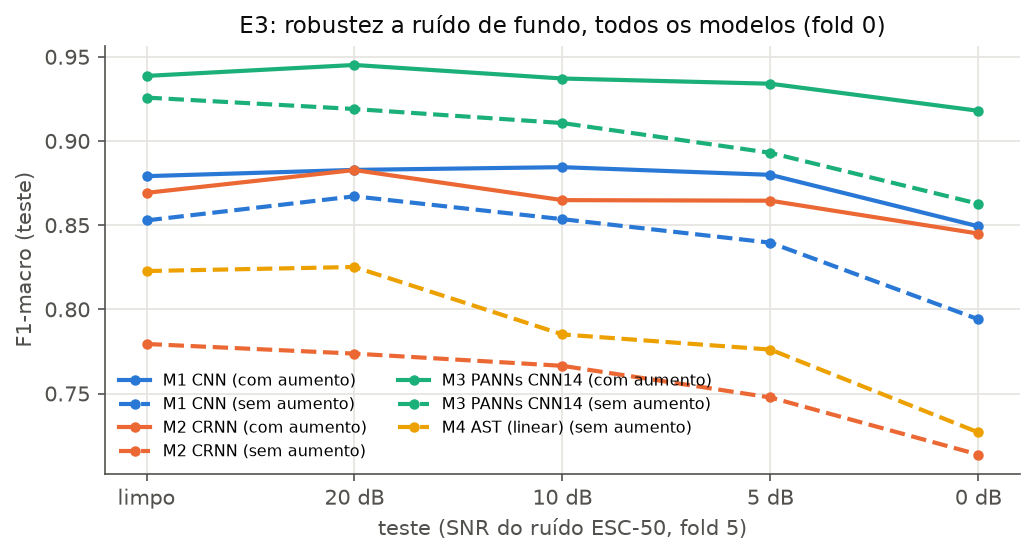

In [8]:
e2b = e.e2b()
display(e2b[["modelo", "aumento", "epocas", "val_f1_macro", "teste_f1_macro"]].set_index(["modelo", "aumento"]).round(3))
e3b = e.e3b()
tab3 = e3b.pivot_table(index=["modelo", "aumento"], columns="teste", values="f1_macro")[["limpo", "20 dB", "10 dB", "5 dB", "0 dB"]]
tab3["queda limpo → 0 dB"] = tab3["0 dB"] - tab3["limpo"]
display(tab3.round(3))
graficos.e3b_linhas(e3b); display(Image("resultados/e3b/e3b_snr.png"))

> **Leitura.**
>
> - **H3: apoiada nos três modelos com as duas versões.** A queda do teste limpo para 0 dB é sempre menor com aumento:
>
>   | modelo | queda sem aumento | queda com aumento |
>   |---|---|---|
>   | M1 | −0,059 | −0,030 |
>   | M2 | −0,065 | −0,024 |
>   | M3 | −0,063 | −0,021 |
>
>   O aumento reduz a queda a menos da metade. Até 5 dB, os modelos com aumento praticamente não perdem nada.
> - **O aumento também melhora o teste limpo**, sobretudo no M2 (de 0,779 para 0,869, **+9 pontos**: a CRNN é a que mais depende dele) e no M1 (+2,6). No M3 o ganho é menor (+1,3), porque o pré-treino já fornece boa parte da robustez.
> - **O M3 com aumento a 0 dB (0,918) é melhor que o M1 com aumento no teste limpo (0,879).** Ruído no nível do próprio canto custa ao M3 menos do que a troca de arquitetura.
> - **O M4 é o mais frágil** (de 0,823 para 0,727, −0,096): sem ajuste fino e sem aumento possível, o embedding congelado não aprende a ignorar o ruído.
> - Ressalva: E2b e E3b usam um treino por configuração (fold 0, semente 42). As diferenças grandes (M2 com e sem aumento, quedas a 0 dB) são bem maiores que a variação entre folds vista no E1 (~0,01); as de ~1 ponto não devem ser lidas isoladamente.

## 7. E4: eficiência de dados (H1)

**O que:** M1, M3 e M4 treinam no fold 0 com 25%, 50% e 100% das gravações de treino (≈ 480, 960 e 1920; estratificado por espécie e aninhado: as 25% estão dentro das 50%). A validação e o teste não mudam.

**Por que:** a segunda metade de H1 diz que o pré-treino ajuda *sobretudo com poucos dados*. Se for verdade, a distância entre M3/M4 e M1 cresce à esquerda da figura.

**Como ler:** compare as curvas; a inclinação mostra quanto cada modelo depende da quantidade de dados.

M1_todas_s42_f0_p25: F1 teste 0.704


M1_todas_s42_f0_p50: F1 teste 0.809


M1_todas_s42_f0: F1 teste 0.879


M3_todas_s42_f0_p25: F1 teste 0.814


M3_todas_s42_f0_p50: F1 teste 0.882


M3_todas_s42_f0: F1 teste 0.939


M4_sem_s42_f0_p25: F1 teste 0.750


M4_sem_s42_f0_p50: F1 teste 0.790


M4_sem_s42_f0: F1 teste 0.823


,25%,50%,100%,ganho 25% → 100%
modelo,,,,
M1,0.704,0.809,0.879,0.175
M3,0.814,0.882,0.939,0.124
M4,0.750,0.790,0.823,0.073


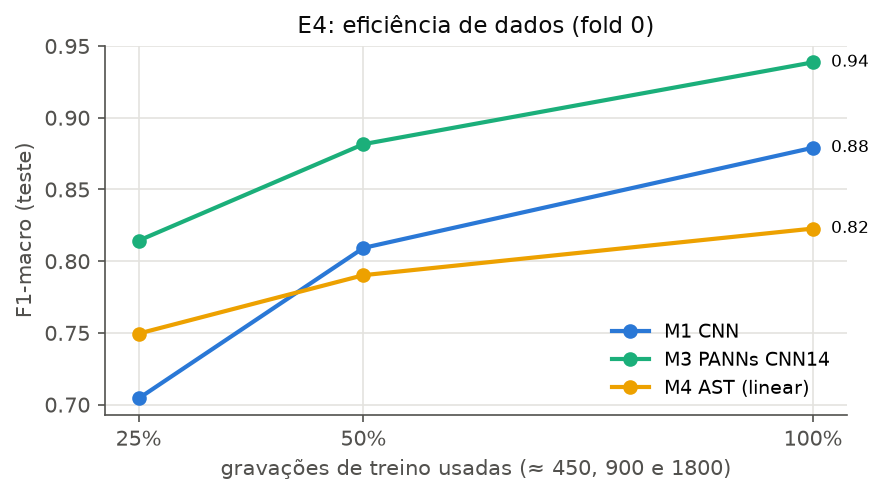

In [9]:
e4 = e.e4()
tab4 = e4.pivot_table(index="modelo", columns="fracao", values="teste_f1_macro")
tab4.columns = [f"{int(c * 100)}%" for c in tab4.columns]
tab4["ganho 25% → 100%"] = tab4["100%"] - tab4["25%"]
display(tab4.round(3))
graficos.e4_curva(e4); display(Image("resultados/e4/e4_fracao.png"))

> **Leitura.**
>
> - **H1, segunda metade ("sobretudo com poucos dados"): apoiada para o M3.** A vantagem do M3 sobre o M1 é de **+0,110 com 25%** dos dados (0,814 contra 0,704), +0,073 com 50% e +0,060 com 100%: cresce quando os dados diminuem.
> - **Com metade dos dados, o M3 (0,882) já supera o M1 com todos (0,879).** Na prática, o pré-treino vale mais que dobrar a quantidade de gravações rotuladas.
> - **O M4 é o que menos depende de dados** (ganho de 25% para 100%: +0,073, contra +0,175 do M1), como se espera de uma representação fixa. Com 25% ele supera o M1 (0,750 contra 0,704), mas com 50% já fica atrás. Para conjuntos muito pequenos, um *linear probe* é uma linha de base barata e razoável.
> - O M1 com 25% usou as 30 épocas sem parar antes, então poderia ganhar um pouco com mais épocas. Mesmo assim, a distância para o M3 (11 pontos) é grande demais para ser explicada por isso.

## 8. Análises: onde e por que os modelos erram

### 8.1 F1 por espécie

**O que:** F1 de cada espécie no teste, para o ensemble dos 5 folds de cada modelo.
**Por que:** o F1-macro é uma média; ela pode esconder que um modelo é muito melhor em poucas espécies difíceis. H1 fala em vantagem "sobretudo nas espécies difíceis".
**Como ler:** espécies ordenadas da mais difícil (em cima) para a mais fácil; cores mais escuras = F1 maior.

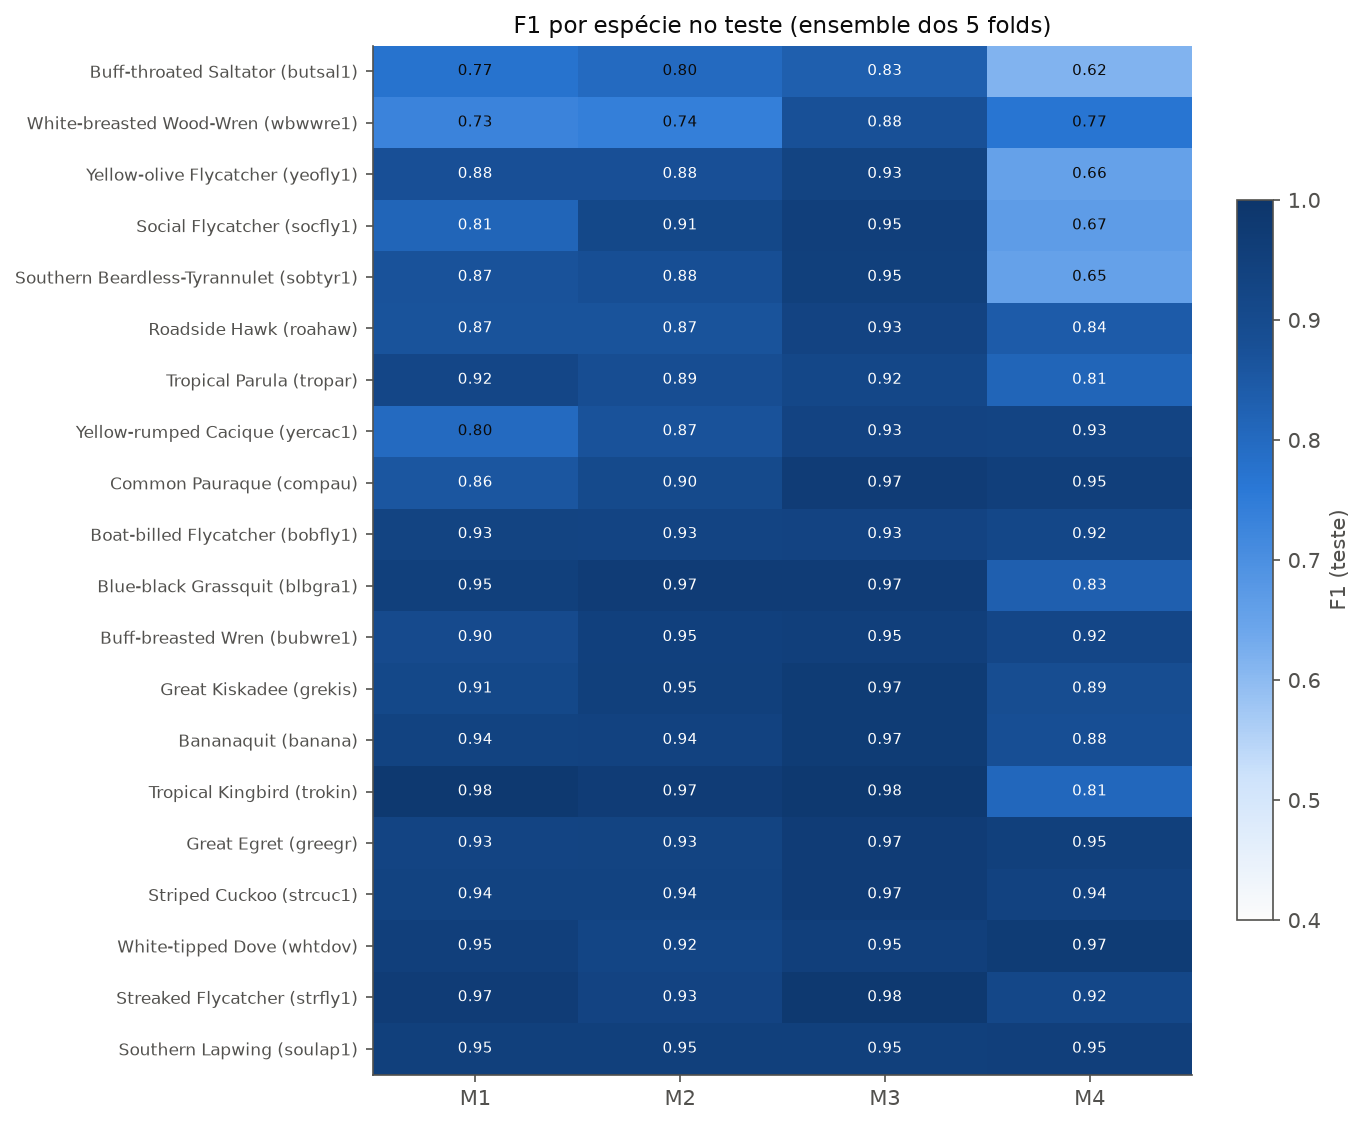

M3 − M1 por espécie: mediana +0.044; M3 melhor em 16 de 20 espécies
5 espécies mais difíceis para o M1 (F1 M1 → M3):
  White-breasted Wood-Wren (wbwwre1): 0.73 → 0.88
  Buff-throated Saltator (butsal1): 0.77 → 0.83
  Yellow-rumped Cacique (yercac1): 0.80 → 0.93
  Social Flycatcher (socfly1): 0.81 → 0.95
  Common Pauraque (compau): 0.86 → 0.97


In [10]:
classes = json.loads(open("resultados/e1/classes.json").read())
y_te = np.load("resultados/e1/y_teste.npy")
probs = {m: e.probs_e1(m, sorted(df1.loc[df1.modelo == m, "fold"])).mean(0) for m in e.MODELOS}
nomes = dados.carregar_metadados().drop_duplicates("primary_label").set_index("primary_label")["common_name"]
f1e = analise.f1_por_especie(y_te, probs, classes)
f1e.index = [f"{nomes.get(c, c)} ({c})" for c in f1e.index]
graficos.f1_especies(f1e, Path("resultados/e1/f1_especies.png"), "F1 por espécie no teste (ensemble dos 5 folds)")
display(Image("resultados/e1/f1_especies.png"))
dif = (f1e["M3"] - f1e["M1"]).sort_values()
print(f"M3 − M1 por espécie: mediana {dif.median():+.3f}; M3 melhor em {(dif > 0).sum()} de {len(dif)} espécies")
print("5 espécies mais difíceis para o M1 (F1 M1 → M3):")
for esp in f1e["M1"].nsmallest(5).index:
    print(f"  {esp}: {f1e.loc[esp, 'M1']:.2f} → {f1e.loc[esp, 'M3']:.2f}")

> **Leitura.**
>
> - O M3 é melhor que o M1 em **16 das 20 espécies** (mediana +0,044).
> - **A vantagem cresce nas espécies difíceis**, como diz H1. Nas 5 piores do M1, o M3 ganha de +0,06 a +0,15:
>   - *White-breasted Wood-Wren*: 0,73 → 0,88;
>   - *Social Flycatcher*: 0,81 → 0,95;
>   - *Yellow-rumped Cacique*: 0,80 → 0,93.
> - As espécies difíceis são em boa parte as mesmas para todos os modelos (topo do mapa). A dificuldade é das espécies (cantos variáveis, parecidos com os de outras), não de uma arquitetura.
> - Ressalva: com ~30 gravações de teste por espécie, cada erro move o F1 da espécie em ~0,03; diferenças pequenas numa espécie isolada não são confiáveis.

### 8.2 Matriz de confusão do melhor modelo

**O que:** para o modelo com maior F1 no teste (ensemble dos folds), a fração de gravações de cada espécie (linha) atribuída a cada espécie (coluna).
**Como ler:** a diagonal são os acertos; manchas fora dela mostram pares de espécies confundidos.

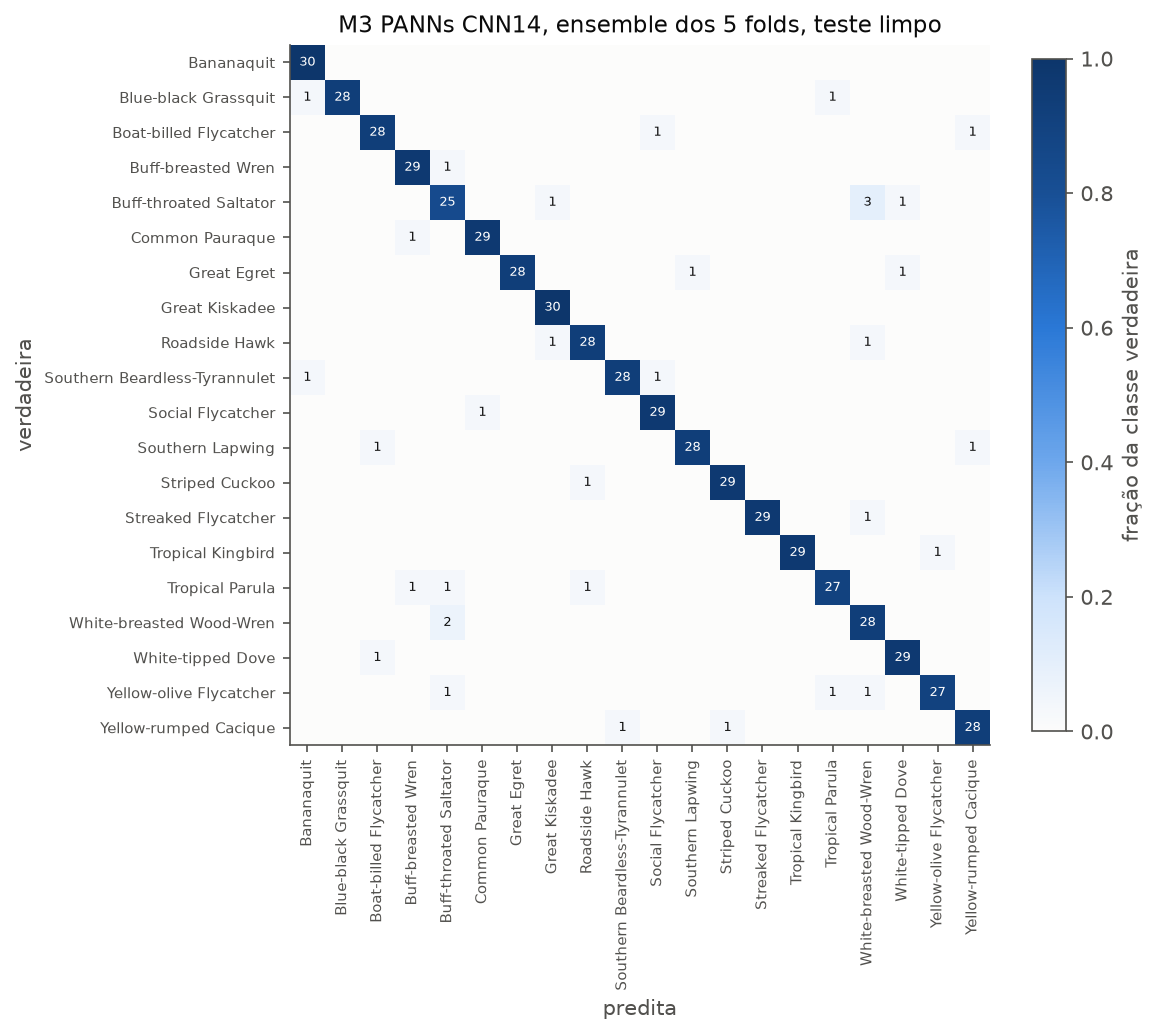

pares mais confundidos (erros nos dois sentidos): Buff-throated Saltator × White-breasted Wood-Wren (5), White-breasted Wood-Wren × Yellow-olive Flycatcher (1), Tropical Parula × Yellow-olive Flycatcher (1)


In [11]:
melhor_modelo = ens1["f1_macro"].idxmax()
graficos.matriz(probs[melhor_modelo], y_te, classes, nomes.to_dict(),
                f"{graficos.NOMES_MODELOS[melhor_modelo]}, ensemble dos 5 folds, teste limpo", Path(f"resultados/e1/matriz_{melhor_modelo}.png"))
display(Image(f"resultados/e1/matriz_{melhor_modelo}.png"))
cm = treino.matriz_confusao(y_te, probs[melhor_modelo], len(classes)); np.fill_diagonal(cm, 0)
pares = sorted(((cm[i, j] + cm[j, i], classes[i], classes[j]) for i in range(len(classes)) for j in range(i + 1, len(classes))), reverse=True)[:3]
print("pares mais confundidos (erros nos dois sentidos):", ", ".join(f"{nomes[a]} × {nomes[b]} ({n})" for n, a, b in pares))

> **Leitura.** A diagonal é quase toda acima de 90%, e os erros do melhor modelo (M3) se concentram num par: **Buff-throated Saltator × White-breasted Wood-Wren** (5 erros somando os dois sentidos; os outros pares têm no máximo 1). São duas espécies de canto melodioso e assobiado, na mesma faixa de frequência, e as duas estão entre as mais difíceis da seção anterior. Fora esse par, os erros são isolados, sem confusão sistemática.

### 8.3 Vazamento por gravador

**O que:** separa o teste em gravações cujo **autor** (quem gravou, no xeno-canto) também aparece no treino e gravações de autores que só aparecem no teste.
**Por que:** a divisão é por gravação, mas o mesmo gravador costuma subir várias gravações da mesma espécie, no mesmo lugar e com o mesmo equipamento. Se o modelo acerta muito mais quando o autor está no treino, parte do acerto pode vir de reconhecer o ambiente/microfone, não a ave. Neste subconjunto ~90% das gravações de teste têm o autor no treino (um único autor tem 277 gravações). O notebook 05 (E5.3) refaz a divisão agrupando por autor.
**Como ler:** compare as duas linhas de cada modelo; o grupo "autor só no teste" é pequeno (~60 gravações), então a diferença tem incerteza grande.

In [12]:
arquivos_teste = jan[jan.particao == "teste"].drop_duplicates("filename")["filename"]
vaz = analise.vazamento_autor(pd.Index(arquivos_teste), y_te, probs)
display(vaz.pivot_table(index="modelo", columns="grupo", values=["acuracia", "f1_macro", "gravacoes"]).round(3))

acuracia                                 f1_macro  \
grupo  autor só no teste autor também no treino autor só no teste   
modelo                                                              
M1                 0.914                  0.889             0.871   
M2                 0.914                  0.904             0.907   
M3                 0.931                  0.945             0.912   
M4                 0.914                  0.838             0.878   

                                      gravacoes                         
grupo  autor também no treino autor só no teste autor também no treino  
modelo                                                                  
M1                      0.890              58.0                  542.0  
M2                      0.904              58.0                  542.0  
M3                      0.945              58.0                  542.0  
M4                      0.838              58.0                  542.0

> **Leitura.**
>
> - **Neste teste, não aparece vantagem para gravações de autores vistos no treino.** As 58 gravações de autores novos têm acurácia igual ou maior que as 542 de autores conhecidos:
>   - M1: 0,914 contra 0,889;
>   - M3: 0,931 contra 0,945, a única inversão, dentro da incerteza.
> - O grupo é pequeno: com 58 gravações, cada erro move a acurácia em ~1,7 ponto, e esses autores não são uma amostra aleatória (tendem a ter poucas gravações).
> - A medida mais limpa é o E5.3 do notebook 05, que **refaz a divisão inteira por autor**. Ali o M1 cai de 0,879 para 0,842 no teste (−3,7 pontos) e de 0,858 para 0,814 na validação.
> - Conclusão: há algum otimismo nos números do E1, da ordem de 3 a 4 pontos para o M1. É uma ressalva real, mas pequena perto das diferenças entre modelos (M3 − M1 ≈ 6 pontos), e por isso não muda as conclusões sobre H1 a H3.

### 8.4 t-SNE dos embeddings (M1 × M3)

**O que:** projeta em 2D o vetor que cada modelo calcula antes da camada final, para as 4772 janelas de teste (fold 0).
**Por que:** mostra se o espaço aprendido agrupa as espécies e se o pré-treino gera grupos mais separados.
**Como ler:** cada ponto é uma janela, cada cor uma espécie. Grupos compactos e afastados = espécies fáceis de separar. Os eixos do t-SNE não têm unidade nem significado; só a vizinhança importa.

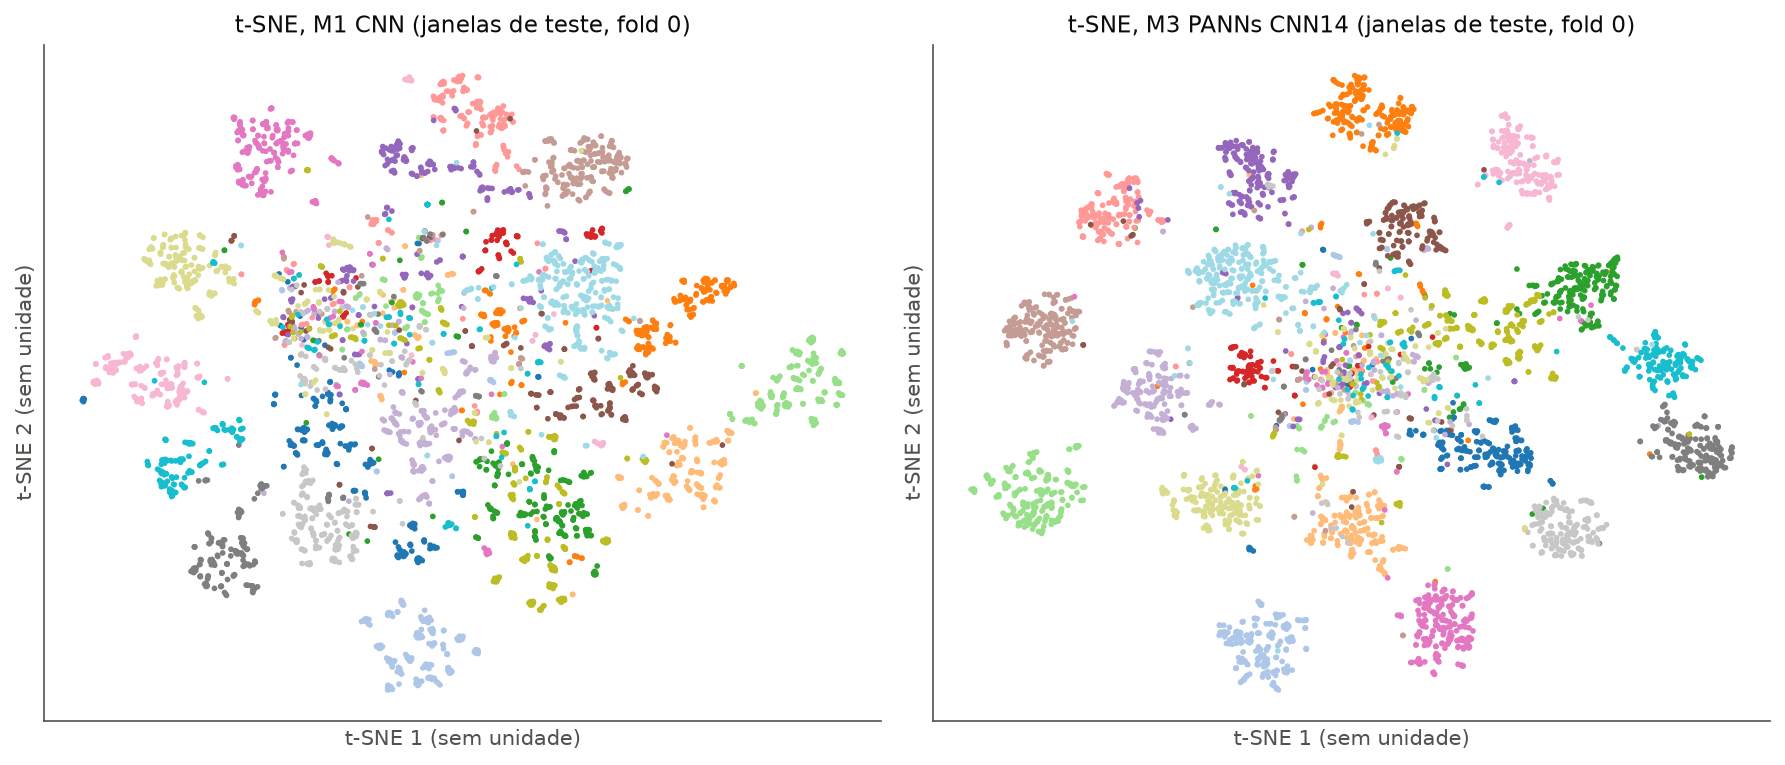

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, m in zip(axs, ["M1", "M3"]):
    X, jm, _ = e.dados_modelo(m)
    idx = np.flatnonzero((jm.particao == "teste").to_numpy())
    rm = carregar_checkpoint(PASTA_CHECKPOINTS / f"{e.nome_execucao(m, 'todas', 42, 0)}.pt", m)
    Z = analise.tsne(analise.embeddings(rm.modelo, X, idx, rm.norm))
    lab = jm.iloc[idx]["primary_label"].map({c: i for i, c in enumerate(classes)})
    ax.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab20", s=3)
    ax.set_title(f"t-SNE, {graficos.NOMES_MODELOS[m]} (janelas de teste, fold 0)")
    ax.set_xlabel("t-SNE 1 (sem unidade)"); ax.set_ylabel("t-SNE 2 (sem unidade)"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig("resultados/e1/tsne_M1_M3.png", bbox_inches="tight", dpi=150); plt.show()

> **Leitura.**
>
> - No **M3**, quase todas as espécies formam grupos compactos e bem afastados.
> - No **M1**, os grupos existem, mas são mais espalhados, e há uma região central grande onde as cores se misturam.
> - Nos dois há um núcleo central misturado. Ele tende a reunir **janelas sem canto** (silêncio, ruído, outro animal): o rótulo é da gravação inteira, então essas janelas recebem a espécie da gravação sem conter informação sobre ela. Isso é rótulo fraco, e é por isso que a média por gravação acerta mais que a janela isolada.
> - A diferença de compacidade é a imagem do que o E1 mede em números: o pré-treino no AudioSet dá ao M3 um espaço de representação em que as espécies já são quase separáveis.

### 8.5 Grad-CAM: o modelo olha para o canto?

**O que:** Grad-CAM mostra quais regiões do espectrograma mais aumentam a pontuação da classe prevista, para 4 janelas de teste, no M1 e no M3.
**Por que:** um modelo que acerta olhando para o ruído de fundo (e não para o canto) não generaliza; é um sinal do vazamento discutido em 8.3.
**Como ler:** linha de cima = log-Mel; linhas de baixo = mapa sobreposto (vermelho = mais importante). Bom sinal: o vermelho cai sobre os traços do canto.

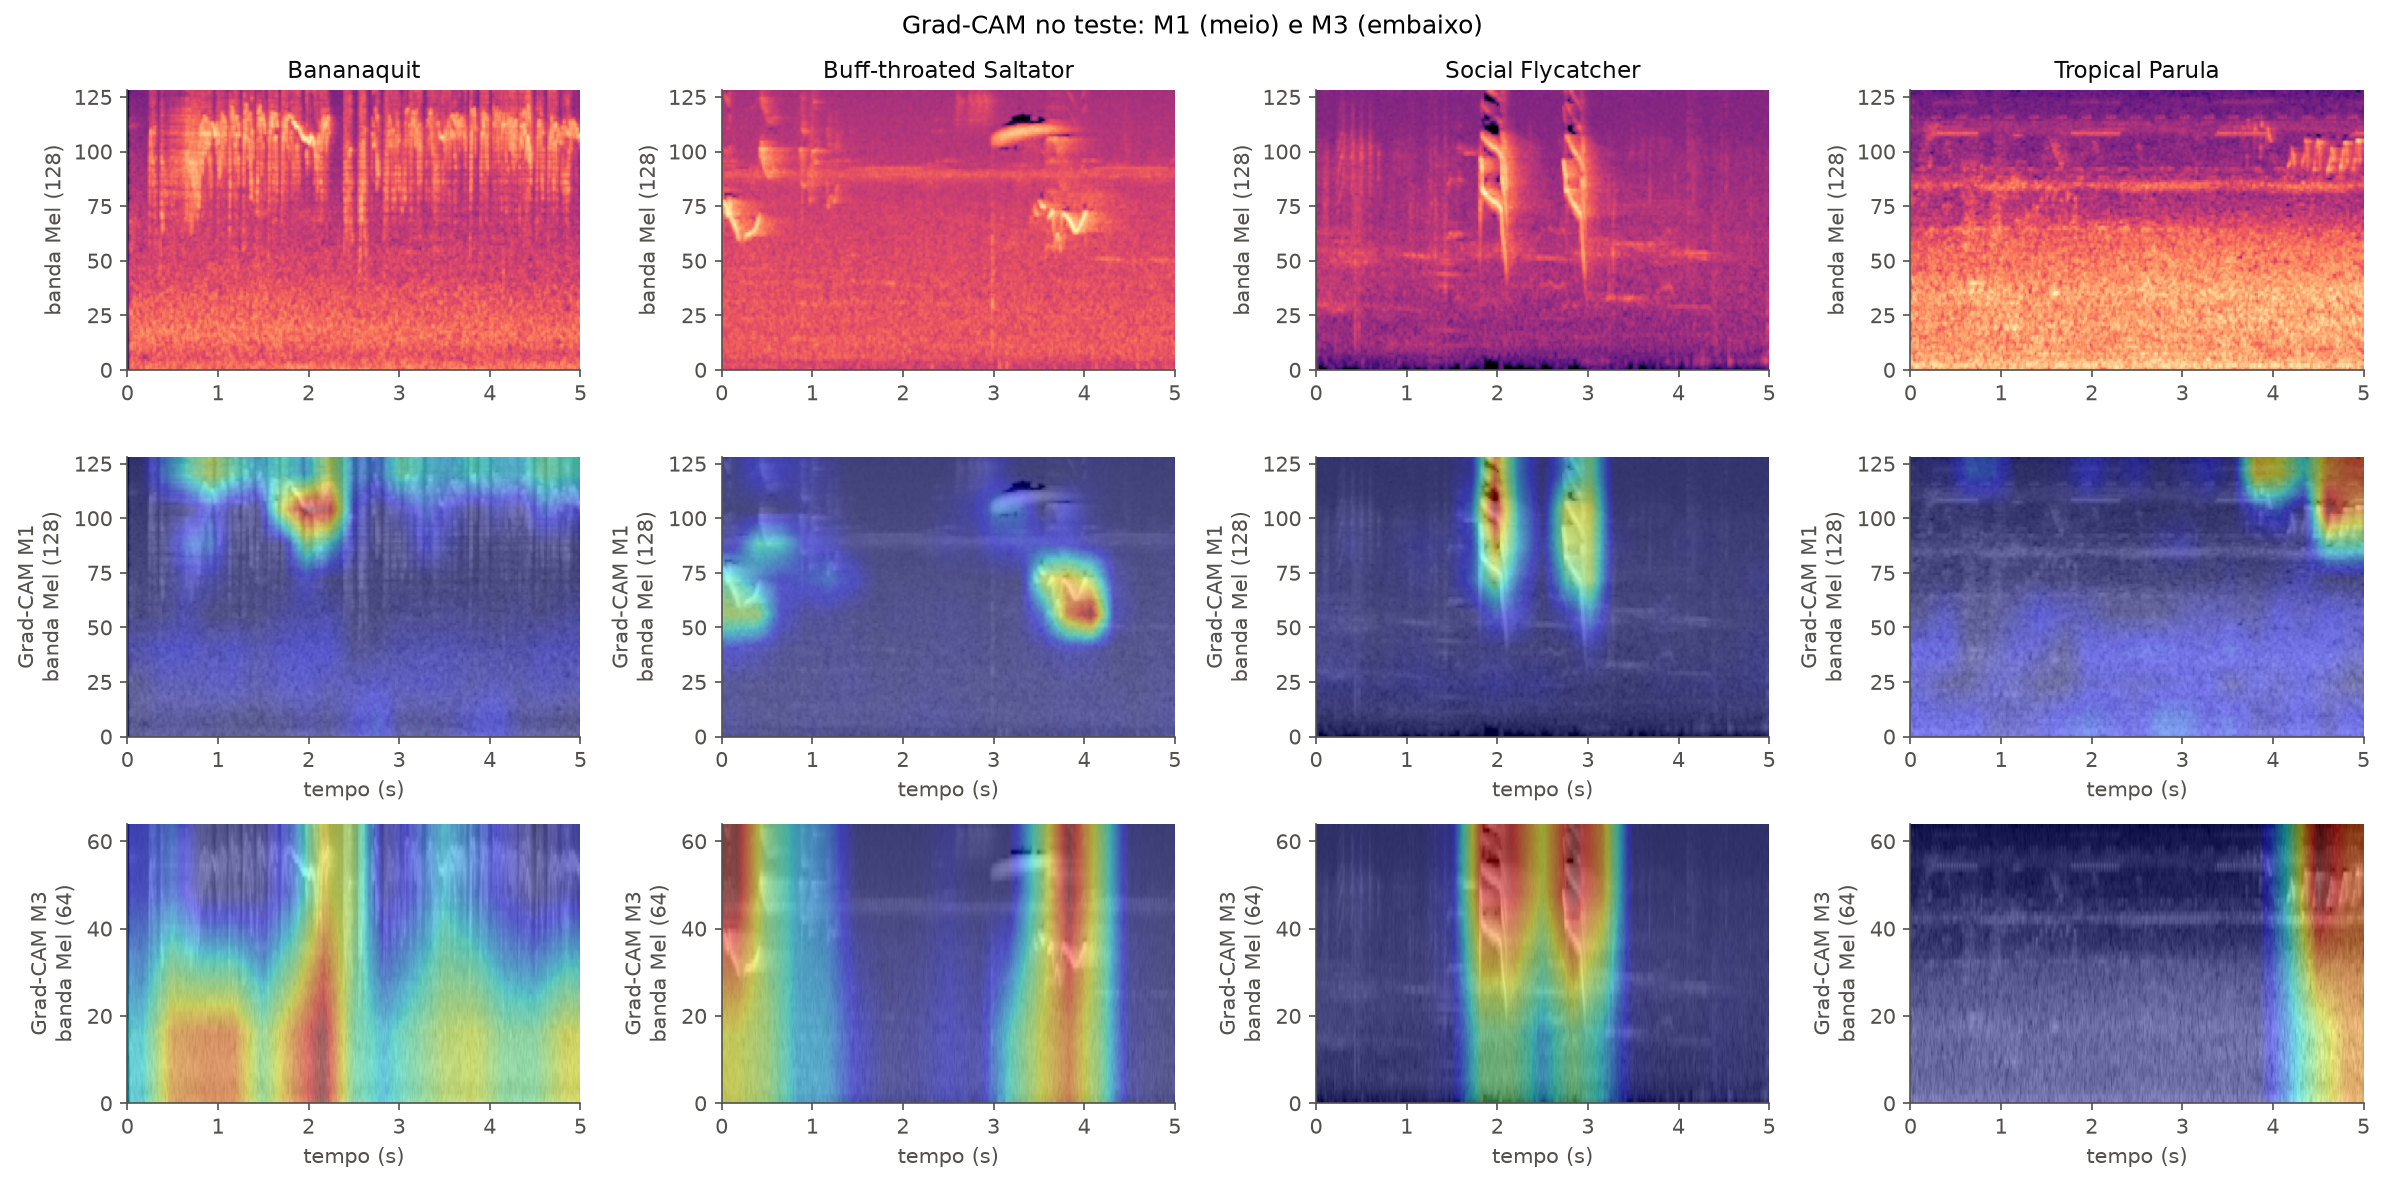

In [14]:
idx4 = np.flatnonzero((jan.particao == "teste").to_numpy())[::1200][:4]
fig, axs = plt.subplots(3, len(idx4), figsize=(4 * len(idx4), 8))
for linha, m in ((1, "M1"), (2, "M3")):
    X, jm, _ = e.dados_modelo(m)
    rm = carregar_checkpoint(PASTA_CHECKPOINTS / f"{e.nome_execucao(m, 'todas', 42, 0)}.pt", m)
    # última camada convolucional de cada modelo (a escolha padrão do Grad-CAM). No M3, a conv_block5
    # dava mapas vazios em 3 de 4 janelas (o gradiente médio por canal saía negativo e o ReLU zerava tudo);
    # a conv_block6 explica a camada que de fato alimenta o pooling, mas tem só 2 posições na frequência:
    # o mapa do M3 diz sobretudo *quando*, não em que banda.
    camada = rm.modelo.extrator[-1] if m == "M1" else rm.modelo.conv_block6
    for j, i in enumerate(idx4):
        x = torch.from_numpy(np.asarray(X[i], dtype=np.float32)).to(next(rm.modelo.parameters()).device)
        cam = analise.grad_cam(rm.modelo, camada, (x - rm.norm[0]) / rm.norm[1])
        xs = np.asarray(X[i], dtype=np.float32)
        if linha == 1:
            axs[0, j].imshow(xs, origin="lower", aspect="auto", cmap="magma", extent=[0, 5, 0, xs.shape[0]])
            axs[0, j].set_title(f"{nomes[jan.primary_label.iloc[i]]}"); axs[0, j].set_ylabel("banda Mel (128)")
        axs[linha, j].imshow(xs, origin="lower", aspect="auto", cmap="gray", extent=[0, 5, 0, xs.shape[0]])
        axs[linha, j].imshow(cam, origin="lower", aspect="auto", cmap="jet", alpha=0.45, extent=[0, 5, 0, xs.shape[0]])
        axs[linha, j].set_ylabel(f"Grad-CAM {m}\nbanda Mel ({xs.shape[0]})"); axs[linha, j].set_xlabel("tempo (s)")
for a in axs.ravel(): a.grid(False)
fig.suptitle("Grad-CAM no teste: M1 (meio) e M3 (embaixo)"); fig.tight_layout()
fig.savefig("resultados/e1/gradcam_M1_M3.png", bbox_inches="tight", dpi=130); plt.show()

> **Leitura.**
>
> - **No M1**, o mapa cai sobre os traços do canto nas quatro janelas:
>   - as duas notas descendentes do *Social Flycatcher* (em ~2 s e ~3 s);
>   - as frases do *Buff-throated Saltator* (em ~0,3 s e ~3,8 s);
>   - o trinado final do *Tropical Parula*, em vez das linhas horizontais contínuas de ruído do fundo.
>
>   É um bom sinal: o modelo usa o canto, não o ambiente.
> - **No M3**, a última camada convolucional tem só 2 posições na frequência, então o mapa é quase uma faixa vertical e indica sobretudo *em que instante* está a evidência. Também aqui os instantes coincidem com os cantos: as duas notas do *Social Flycatcher*, as frases do *Saltator* e o trinado final do *Parula*, ignorando os trechos só com ruído.
> - O Grad-CAM é uma ferramenta qualitativa, com 4 exemplos: serve para detectar um problema grosseiro (o modelo olhar só para o fundo), que não aparece aqui, mas não prova que o modelo nunca usa o ambiente.

## 9. Pesos finais reutilizáveis e inferência

**O que:** escolhe o melhor modelo de cada tipo e salva em `checkpoints/finais/<tipo>.pt`, com um `<tipo>.json` ao lado (classes, normalização, configuração do log-Mel, hiperparâmetros, métricas de validação e teste, data). Também salva o *ensemble* (média ponderada das probabilidades, pesos no `ensemble.json`), com uma **temperatura de calibração** ajustada na mesma validação (seção 5.7 do notebook 05): sem ela, o ensemble diz ~70% de confiança quando acerta ~93%; com ela, a porcentagem mostrada pela inferência corresponde à chance real de acerto. A temperatura não muda a espécie prevista nem o F1.

**Como a escolha é feita (sem olhar o teste):** para cada tipo, entre a execução do fold 0 do E1 e as variantes testadas no notebook 05 (E5), fica a de maior **F1 na validação do fold 0**, a única validação comum a todos os modelos. Os pesos do ensemble também são escolhidos nessa validação. O teste só é reportado.

**Inferência:** `python -m birdclef.inferencia caminho.ogg [--modelo M1|M2|M3|M4|M4FT|M5|ensemble]` repete o caminho do treino: lê o áudio a 32 kHz, recorta as janelas de 5 s (mesmo filtro de energia), calcula a entrada de cada modelo, aplica a mesma normalização, faz a média das janelas e devolve as 3 espécies mais prováveis.

In [15]:
from birdclef import finais
resumo_finais = finais.criar()
display(resumo_finais.set_index("final").round(3))

,origem,descricao,candidatos,val_f1,teste_f1,parametros
final,,,,,,
M1,checkpoints/M1PCEN_todas_s42_f0.pt,PCEN no lugar do log,5.0,0.869,0.902,3.935e+05
M2,checkpoints/M2_todas_s42_f0.pt,"E1, fold 0",2.0,0.848,0.869,3.746e+05
M3,checkpoints/M3_todas_s42_f0.pt,"E1, fold 0",2.0,0.923,0.939,7.971e+07
M4,checkpoints/M4_sem_s42_f0.pt,"E1, fold 0",1.0,0.839,0.823,1.538e+04
M4FT,checkpoints/M4FT_sem_s42_f0.pt,AST com os 2 últimos blocos ajustados,1.0,0.848,0.853,1.419e+07
M5,checkpoints/M5_todas_s42_f0.pt,EfficientNet-B0 ImageNet,1.0,0.904,0.923,4.033e+06
ensemble,M1×0.35 + M2×0.10 + M3×0.55,média ponderada das probabilidades por gravaçã...,NaN,0.934,0.950,NaN


In [16]:
# Demonstração: uma gravação do teste (nunca vista no treino), pela linha de comando e pela função
import subprocess
from birdclef.inferencia import prever_arquivo
exemplo = div[div.particao == "teste"].sort_values("filename").iloc[7]
caminho = f"dados/bruto/train_audio/{exemplo.filename}"
print(f"espécie verdadeira: {exemplo.primary_label} ({exemplo.common_name})\n")
saida = subprocess.run([sys.executable, "-m", "birdclef.inferencia", caminho, "--modelo", "ensemble"],
                       capture_output=True, text=True, encoding="utf-8")
print(saida.stdout or saida.stderr)
display(pd.DataFrame([{"modelo": m, **{f"top-{k + 1}": f"{r['nome']} ({100 * r['probabilidade']:.0f}%)" for k, r in enumerate(prever_arquivo(caminho, m))}}
                      for m in ["M1", "M2", "M3", "M4", "ensemble"]]).set_index("modelo"))

espécie verdadeira: banana (Bananaquit)



dados/bruto/train_audio/banana/XC351514.ogg: 12 janela(s) de 5 s | modelo ensemble
  1. banana   Bananaquit                        98.8%
  2. butsal1  Buff-throated Saltator             0.4%
  3. wbwwre1  White-breasted Wood-Wren           0.2%



,top-1,top-2,top-3
modelo,,,
M1,Bananaquit (33%),White-breasted Wood-Wren (10%),Yellow-rumped Cacique (6%)
M2,Bananaquit (65%),Buff-throated Saltator (9%),Tropical Parula (4%)
M3,Bananaquit (87%),Buff-throated Saltator (4%),Boat-billed Flycatcher (2%)
M4,Bananaquit (77%),Buff-throated Saltator (10%),Yellow-olive Flycatcher (4%)
ensemble,Bananaquit (99%),Buff-throated Saltator (0%),White-breasted Wood-Wren (0%)


> **Leitura.**
>
> - **Escolhas pela validação do fold 0:**
>   - para o **M1**, a variante com **PCEN** do notebook 05 (validação 0,869 contra 0,858 do E1), que no teste dá **0,902**, contra 0,879 do M1 original;
>   - para os outros tipos, a execução do E1 venceu as variantes testadas.
> - **O ensemble final** (M1 com PCEN 0,35 + M2 0,10 + M3 0,55) é o melhor resultado do projeto: **F1 de 0,950 no teste**. Ele supera o M3 sozinho (0,939) porque o M1 com PCEN erra em gravações diferentes das do M3.
> - **Tamanhos:** M1 e M2 têm ~1,6 MB e rodam na CPU em fração de segundo; o M3 tem ~320 MB.
> - **Demonstração:** a gravação de teste (*Bananaquit*) é reconhecida por todos os modelos, cada um com sua confiança (os modelos individuais não são calibrados). O ensemble mostra a probabilidade **já calibrada**.
> - **Reprodutibilidade:** os pesos e o JSON de cada final ficam em `checkpoints/finais/`. A seção "Como usar os pesos" do README explica como baixar o PANNs e o AST e recriar os finais.

## 10. Conclusões

**Hipóteses**

| | Hipótese | Resultado | Evidência |
|---|---|---|---|
| **H1** | pré-treinados superam os treinados do zero, sobretudo com poucos dados | **apoiada para o ajuste fino (M3), rejeitada para o pré-treino congelado (M4)** | M3 − M1 = +0,058 nos 5 folds (IC95 do ensemble [+0,029; +0,076]); vantagem de +0,110 com 25% dos dados; maior nas espécies difíceis. O M4 perde do M1 (−0,056) |
| **H2** | a CRNN (M2) supera a CNN (M1) de mesmo porte | **não apoiada** | M2 − M1 = −0,013 por fold (ganha em 2 de 5); ensemble +0,013 com IC [−0,005; +0,031], que inclui zero. O M2 é muito mais instável (desvio 0,045 contra 0,008) |
| **H3** | o aumento de dados reduz a queda sob ruído | **apoiada** | queda do limpo para 0 dB com aumento contra sem aumento: M1 −0,030 contra −0,059; M2 −0,024 contra −0,065; M3 −0,021 contra −0,063 |

**Mensagens principais**

1. **O pré-treino em áudio com ajuste fino é o que mais ajuda:** o M3 chega a 0,938 ± 0,008 (0,944 no ensemble dos folds, top-3 de 0,992). Com metade dos dados ele já supera o M1 com todos.
2. **Pré-treino sem adaptação não basta:** o AST congelado (M4) fica abaixo da CNN pequena treinada do zero. Ajustar só os 2 últimos blocos (notebook 05) já o melhora (0,853 contra 0,823).
3. **Modelar o tempo com GRU não compensou** com janelas de 5 s e o orçamento usado. A CRNN depende muito de aumento de dados (+9 pontos) e é instável entre folds.
4. **O aumento de dados é barato e funciona** em todos os modelos: melhora o teste limpo e reduz a queda sob ruído a menos da metade.
5. **O melhor sistema final**, ensemble de M1 com PCEN, M2 e M3, chega a **0,950** no teste (seção 9 e notebook 05).

**Limitações**

- **Dados curados:** 20 espécies comuns, gravações do xeno-canto com nota ≥ 4, classes equilibradas (150 por espécie). Gravações de campo (*soundscapes*), com várias aves sobrepostas, espécies raras e desequilíbrio, são muito mais difíceis. Os números servem para **comparar modelos**, não para estimar o desempenho em campo.
- **Gravadores repetidos:** a divisão é por gravação, e 90% das gravações de teste têm o autor no treino. A divisão por autor (E5.3) custa ~3,7 pontos ao M1.
- **Ruído sintético:** o teste ruidoso mistura clipes da ESC-50 a SNRs controladas. É um substituto razoável, mas não equivale a ruído real de campo. O sorteio exato de clipes da Parte 1 não pôde ser reproduzido (nota da seção 6).
- **Uma semente no E2b, no E3b e no E4:** diferenças de ~1 ponto nesses experimentos estão dentro da variação entre treinos.
- **Comparação com o M4 desigual por construção:** o M4 não usa aumento nem ajuste fino, por limite de memória (4 GB de VRAM).
- **Hiperparâmetros não otimizados por modelo:** M1 e M2 usam os mesmos de propósito (para H2), e o M3, valores padrão de ajuste fino. Cada modelo poderia melhorar com busca própria.

**Trabalhos futuros**

- Avaliar nos *soundscapes* do BirdCLEF (várias espécies por janela, rótulo multi-label).
- Aumentar o número de espécies, incluindo as raras, e tratar o desequilíbrio.
- Usar a divisão por autor como padrão nas comparações.
- Ajuste fino completo do AST e modelos de áudio mais recentes (BEATs, BirdNET, Perch), numa GPU maior.
- Combinar a PCEN, a melhoria mais forte no M1, com os modelos pré-treinados.
- Destilação mais cuidadosa do M3 para a CNN pequena (outras temperaturas e pesos), buscando um modelo leve com desempenho próximo ao do M3.